task3 : Natural Language Processing(NLP)-sentiment analysis

In [4]:
#importing datasets
import pandas as pd
df=pd.read_csv('cleaned_sentiment_dataset.csv')
display(df)




,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...
707,Collaborating on a science project that receiv...,Happy,2017-08-18 18:20:00,ScienceProjectSuccessHighSchool,Facebook,#ScienceFairWinner #HighSchoolScience,20.0,39.0,UK,2017,8,18,18
708,Attending a surprise birthday party organized ...,Happy,2018-06-22 14:15:00,BirthdayPartyJoyHighSchool,Instagram,#SurpriseCelebration #HighSchoolFriendship,25.0,48.0,USA,2018,6,22,14
709,Successfully fundraising for a school charity ...,Happy,2019-04-05 17:30:00,CharityFundraisingTriumphHighSchool,Twitter,#CommunityGiving #HighSchoolPhilanthropy,22.0,42.0,Canada,2019,4,5,17
710,"Participating in a multicultural festival, cel...",Happy,2020-02-29 20:45:00,MulticulturalFestivalJoyHighSchool,Facebook,#CulturalCelebration #HighSchoolUnity,21.0,43.0,UK,2020,2,29,20


In [5]:
import re
import nltk
from textblob import TextBlob
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.tokenize import word_tokenize

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

stem = PorterStemmer().stem

def clean(text):
    words= re.sub(r"[^a-zA-Z]", " ", text.lower()).split()
    return " ".join(stem(w) for w in words if w not in stop_words)

df['cleaned_txt']=df['Text'].apply(clean)
df[["Text","cleaned_txt"]].head()





[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Text,cleaned_txt
0,Enjoying a beautiful day at the park! ...,enjoy beauti day park
1,Traffic was terrible this morning. ...,traffic terribl morn
2,Just finished an amazing workout! 💪 ...,finish amaz workout
3,Excited about the upcoming weekend getaway! ...,excit upcom weekend getaway
4,Trying out a new recipe for dinner tonight. ...,tri new recip dinner tonight


In [6]:
#sentiments score
df['Score']=df['cleaned_txt'].apply(lambda x: TextBlob(x).sentiment.polarity)
df['Sentiment']=df['Score'].apply(
    lambda x: 'Positive' 
    if x>0 
    else ('Negative' if x<0 else 'Neutral')
)
df['Sentiment'].value_counts()


Sentiment
Neutral     378
Positive    223
Negative    111
Name: count, dtype: int64

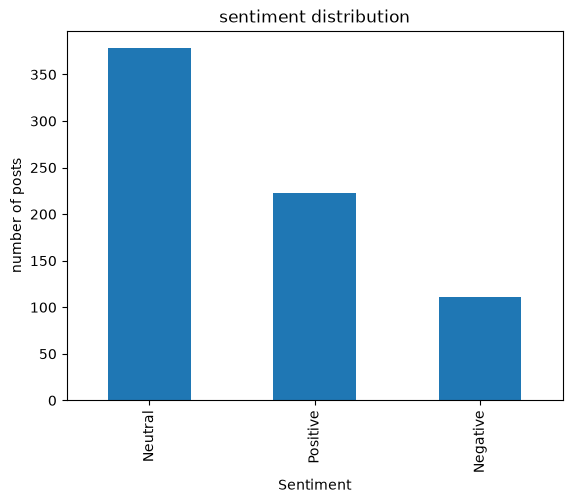

In [7]:
#sentiments distribution
import matplotlib.pyplot as plt 
df['Sentiment'].value_counts().plot(kind='bar')
plt.title("sentiment distribution")
plt.xlabel("Sentiment")
plt.ylabel("number of posts")
plt.show()

interp: neutral sentiment is more frequent

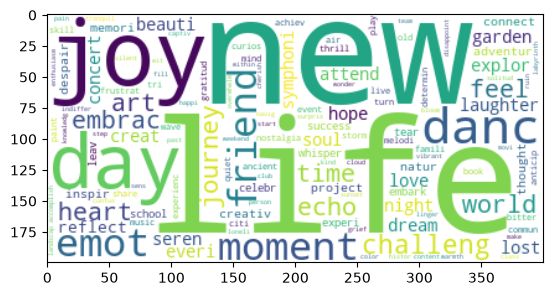

In [13]:
#word frequencies
from wordcloud import WordCloud

t=" ".join(df['cleaned_txt'])
wordcloud=WordCloud(background_color='white').generate(t)
plt.imshow(wordcloud, interpolation='bilinear')
plt.show()